When is the best time of year to find slugs and snails?
* How do the number of slugs and snails found by biologists change over time in this data set?
* How do the number of slug and snail species found by biologists change over time in this data set?

In [391]:
import pandas as pd
import numpy as np
data = pd.read_csv("Slugs+and+Snails.csv")
data.info()
print(data.describe())
data.head(20)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3587 entries, 0 to 3586
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Project.Name    3587 non-null   object 
 1   UNIT            3587 non-null   object 
 2   SEARCH.AREA     3587 non-null   object 
 3   Time            3587 non-null   object 
 4   Date            3587 non-null   object 
 5   EASTING         3572 non-null   float64
 6   NORTHING        3570 non-null   float64
 7   MolluskCode     3587 non-null   object 
 8   ScientificName  3587 non-null   object 
 9   Type            3587 non-null   object 
 10  CommonName      3587 non-null   object 
 11  Count           3587 non-null   int64  
dtypes: float64(2), int64(1), object(9)
memory usage: 336.4+ KB
            EASTING      NORTHING        Count
count  3.572000e+03  3.570000e+03  3587.000000
mean   4.860482e+05  5.009697e+06     1.950655
std    2.132638e+05  3.299014e+05     1.792675
min    4.64

,Project.Name,UNIT,SEARCH.AREA,Time,Date,EASTING,NORTHING,MolluskCode,ScientificName,Type,CommonName,Count
0,Nehalem,31-1,SA1,2011-10-28 15:00:00,2011-10-28,492073.0,5080757.0,VECO,Vespericola columbianus,Snail,Northwest Hesperian snail,2
1,Nehalem,31-1,SA10,2011-10-28 16:45:00,2011-10-28,492064.0,5080488.0,ARCO,Ariolimax columbiana,Slug,Banana slug,1
2,Nehalem,31-1,SA10,2011-10-28 16:45:00,2011-10-28,492064.0,5080488.0,VECO,Vespericola columbianus,Snail,Northwest Hesperian snail,2
3,Nehalem,31-1,SA12,2011-10-27 17:45:00,2011-10-27,492186.0,5080244.0,ANSP,Ancotrema sportella,Snail,Beaded lancetooth snail,1
4,Nehalem,31-1,SA13,2011-10-28 08:00:00,2011-10-28,492265.0,508029.0,HAVA,Haplotrema vancouverense,Snail,Robust lancetooth snail,3
5,Nehalem,31-1,SA14,2011-10-27 16:30:00,2011-10-27,492152.0,508008.0,HAsp,Haplotrema sp.,Snail,Unknown member of Haplotrema genus,2
6,Nehalem,31-1,SA14,2011-10-27 16:30:00,2011-10-27,492152.0,508008.0,VECO,Vespericola columbianus,Snail,Northwest Hesperian snail,2
7,Nehalem,31-1,SA2,2011-10-28 14:15:00,2011-10-28,492162.0,5080813.0,HAVA,Haplotrema vancouverense,Snail,Robust lancetooth snail,3
8,Nehalem,31-1,SA7,2011-10-28 16:00:00,2011-10-28,492269.0,5080545.0,HAsp,Haplotrema sp.,Snail,Unknown member of Haplotrema genus,2
9,Nehalem,31-1,SA7,2011-10-28 16:00:00,2011-10-28,492269.0,5080545.0,VECO,Vespericola columbianus,Snail,Northwest Hesperian snail,1


In [392]:
# selecting only the required columns
data_s = data[['Date', 'Time', 'MolluskCode', 'ScientificName', 'Type', 'Count']]
data_s['Time'] = pd.to_datetime(data_s['Time'])
data_s['YearMonth'] = data_s['Time'].dt.to_period('M')
filtered_df = data_s[data_s['Type'].isin(['Slug', 'Snail'])]
print(filtered_df.info())
filtered_df.head(20)
print(filtered_df['YearMonth'].unique())

<class 'pandas.core.frame.DataFrame'>
Index: 3370 entries, 0 to 3586
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            3370 non-null   object        
 1   Time            3370 non-null   datetime64[ns]
 2   MolluskCode     3370 non-null   object        
 3   ScientificName  3370 non-null   object        
 4   Type            3370 non-null   object        
 5   Count           3370 non-null   int64         
 6   YearMonth       3370 non-null   period[M]     
dtypes: datetime64[ns](1), int64(1), object(4), period[M](1)
memory usage: 210.6+ KB
None
<PeriodArray>
['2011-10', '2011-11', '2006-06', '2006-11', '2006-05', '2011-06', '2012-06',
 '2011-12', '2012-11', '2012-05']
Length: 10, dtype: period[M]


/var/folders/p9/frtk4fwx3nzdw7xqnvjwz2sw0000gn/T/ipykernel_74427/2325682606.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_s['Time'] = pd.to_datetime(data_s['Time'])
/var/folders/p9/frtk4fwx3nzdw7xqnvjwz2sw0000gn/T/ipykernel_74427/2325682606.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_s['YearMonth'] = data_s['Time'].dt.to_period('M')


In [393]:
time_grouped_counts = filtered_df.groupby(['YearMonth', 'Type'])['Count'].sum().unstack(fill_value=0)
time_grouped_counts.head(100)


Type,Slug,Snail
YearMonth,,
2006-05,231,1065
2006-06,120,637
2006-11,46,2468
2011-06,196,794
2011-10,35,131
2011-11,64,261
2011-12,10,52
2012-05,62,193
2012-06,136,219


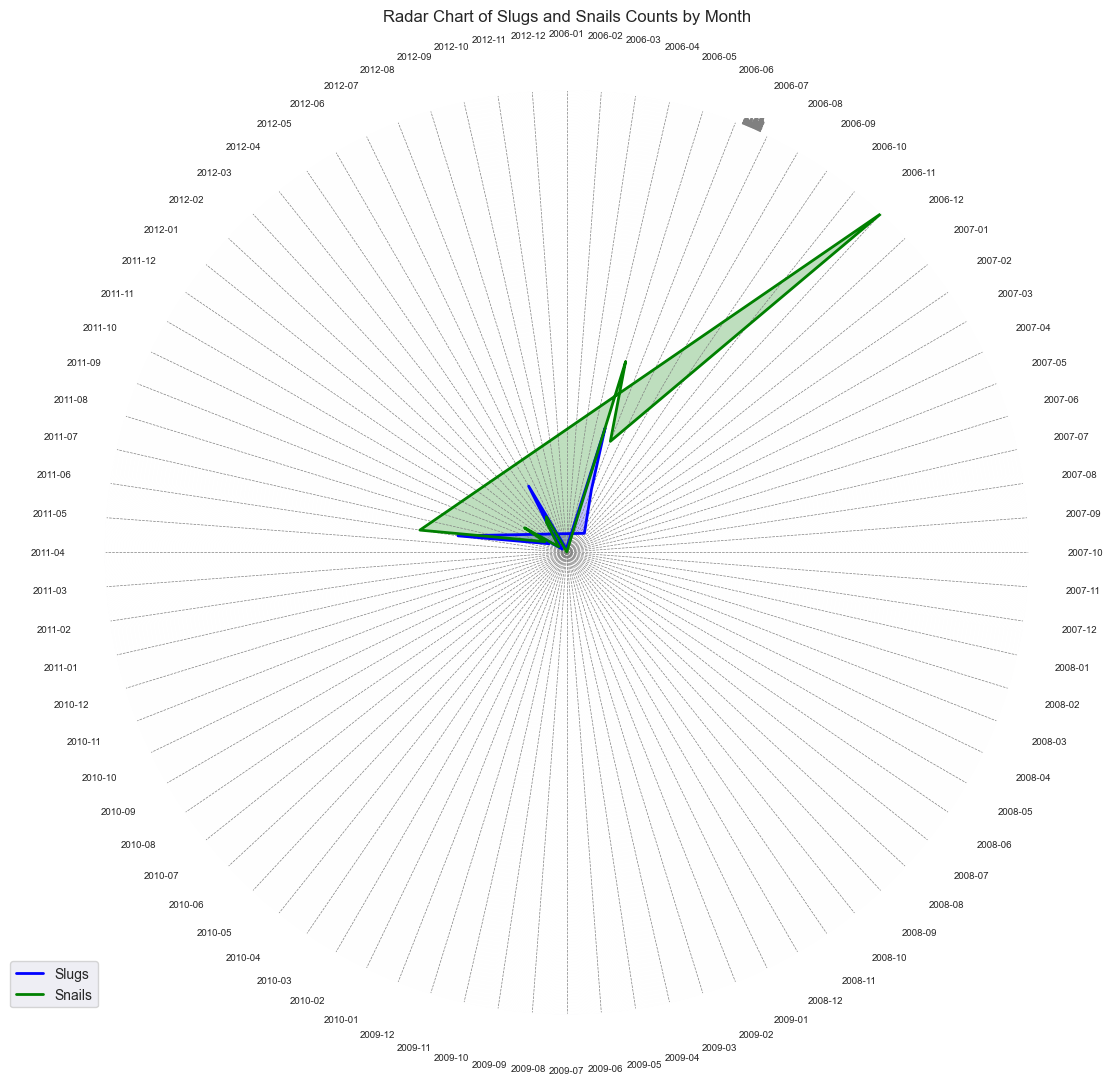

In [394]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for radar plot
categories = time_grouped_counts.index.astype(str).tolist()  # Months
values_slug = time_grouped_counts['Slug'].values.flatten().tolist()
values_snail = time_grouped_counts['Snail'].values.flatten().tolist()
maxslug = max(values_slug) + 1
maxsnail = max(values_snail) + 1
maxvalue = max(maxslug, maxsnail)
# Radar chart setup
N = 84

# Create a list of angles for each category
angles = [n / float(N) * 2 * np.pi for n in range(N)]
i = 0
for year in range(2006, 2013):
    for month in range(1, 13):
        index = str(year) + '-' + str(month).zfill(2)
        if index not in categories:
            categories.insert(i, index)
            values_slug.insert(i, None)
            values_snail.insert(i, None)
        i+=1

values_slug += values_slug[:1]  # Repeat the first value to close the circle
values_snail += values_snail[:1]  # Repeat the first value to close the circle
angles += angles[:1]  # Repeat the first angle to close the circle

# Create the radar chart
plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)
ax.set_theta_offset(np.pi / 2)  # Rotate the plot
ax.set_theta_direction(-1)  # Reverse the direction

# Draw one axe per variable and add labels
plt.xticks(angles[:-1], categories)
plt.tick_params(axis='x', pad=30)  # Increase padding for x-axis labels
for label in ax.get_xticklabels():
    label.set_fontsize(7)

# Draw ylabels
#ax.set_rlabel_position(0)
plt.yticks(range(0, maxvalue, 1), color="grey", size=7)
plt.ylim(0, max(maxslug, maxsnail))


# Plot data
#ax.yaxis.grid(True)  # Enable radial grid lines
# Add radial grid lines
ax.xaxis.grid(True)  # Radial grid lines
ax.xaxis.grid(True)
#ax.grid(color='#AAAAAA')
# Set custom grid lines at intervals of pi/11
grid_spacing = 2 * np.pi / 84
num_grid_lines = int(np.ceil(2 * np.pi / grid_spacing))
# Create grid lines
for i in range(num_grid_lines):
    angle = i * grid_spacing
    ax.plot([angle, angle], [0, maxvalue], color='grey', linewidth=0.5, linestyle='--')

#print(angles, values_snail)
filtered_angles = []
filtered_slug_values = []
filtered_snail_values = []
for i in range(len(angles)):
    if values_snail[i] is not None:
        filtered_angles.append(angles[i])
        filtered_snail_values.append(values_snail[i])
        filtered_slug_values.append(values_slug[i])
filtered_slug_values = list(map(lambda x: x * 3, filtered_slug_values))
#print(filtered_angles)
filtered_angles += filtered_angles[:1]
#print(filtered_angles)
filtered_slug_values += filtered_slug_values[:1]
filtered_snail_values += filtered_snail_values[:1]
ax.plot(filtered_angles, filtered_slug_values, color='blue', linewidth=2, linestyle='solid', label='Slugs')
ax.fill(filtered_angles, filtered_slug_values, color='blue', alpha=0.25)

ax.plot(filtered_angles, filtered_snail_values, color='green', linewidth=2, linestyle='solid', label='Snails')
ax.fill(filtered_angles, filtered_snail_values, color='green', alpha=0.25)

# Add a title and legend
plt.title('Radar Chart of Slugs and Snails Counts by Month')
plt.legend(loc='lower right', bbox_to_anchor=(0, 0))

plt.show()

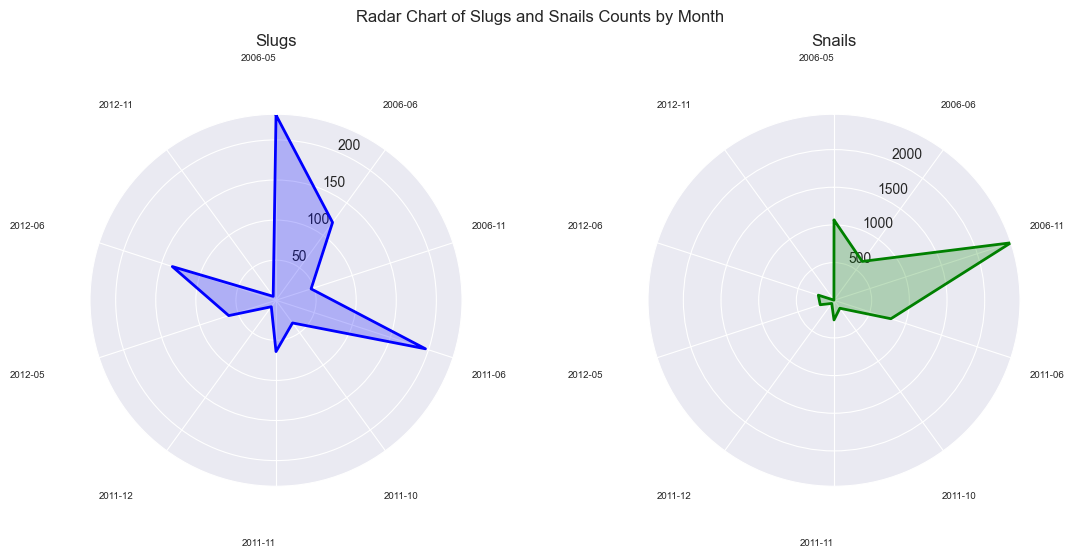

In [404]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data from CSV file
data = pd.read_csv("Slugs+and+Snails.csv")

# Convert 'Date' to datetime and extract Year-Month
data['Date'] = pd.to_datetime(data['Date'])
data['Year-Month'] = data['Date'].dt.to_period('M').astype(str)

# Aggregate counts by Year-Month and Type
grouped_counts = data.groupby(['Year-Month', 'Type'])['Count'].sum().unstack(fill_value=0)

# Prepare data for radar plot
categories = grouped_counts.index.tolist()  # Months
values_slug = grouped_counts['Slug'].values.flatten().tolist()
values_snail = grouped_counts['Snail'].values.flatten().tolist()

# Calculate maximum values for y-axis limits
maxslug = max(values_slug) + 1
maxsnail = max(values_snail) + 1
maxvalue = max(maxslug, maxsnail)

# Radar chart setup
N = len(categories)  # Total number of categories (months)

# Create a list of angles for each category
angles = [n / float(N) * 2 * np.pi for n in range(N)]

# Close the circle for radar chart
values_slug += values_slug[:1]
values_snail += values_snail[:1]
angles += angles[:1]

# Create the figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), subplot_kw={'projection': 'polar'})

# Plot slugs
ax1.set_title('Slugs')
ax1.set_theta_offset(np.pi / 2)  # Rotate the plot
ax1.set_theta_direction(-1)  # Reverse the direction
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(categories, fontsize=7)
for label in ax1.get_xticklabels():
    label.set_rotation(45)
    label.set_horizontalalignment('right')
ax1.tick_params(axis='x', pad=30)
ax1.set_ylim(0, maxslug)
ax1.xaxis.grid(True)
ax1.plot(angles, values_slug, color='blue', linewidth=2, linestyle='solid', label='Slugs')
ax1.fill(angles, values_slug, color='blue', alpha=0.25)

# Plot snails
ax2.set_title('Snails')
ax2.set_theta_offset(np.pi / 2)  # Rotate the plot
ax2.set_theta_direction(-1)  # Reverse the direction
ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(categories, fontsize=7)
for label in ax2.get_xticklabels():
    label.set_rotation(45)
    label.set_horizontalalignment('right')
ax2.tick_params(axis='x', pad=30)
ax2.set_ylim(0, maxsnail)
ax2.xaxis.grid(True)
ax2.plot(angles, values_snail, color='green', linewidth=2, linestyle='solid', label='Snails')
ax2.fill(angles, values_snail, color='green', alpha=0.25)

# Adjust spacing between subplots
plt.subplots_adjust(wspace=0.5)

# Add a title for the figure
fig.suptitle('Radar Chart of Slugs and Snails Counts by Month')

plt.show()


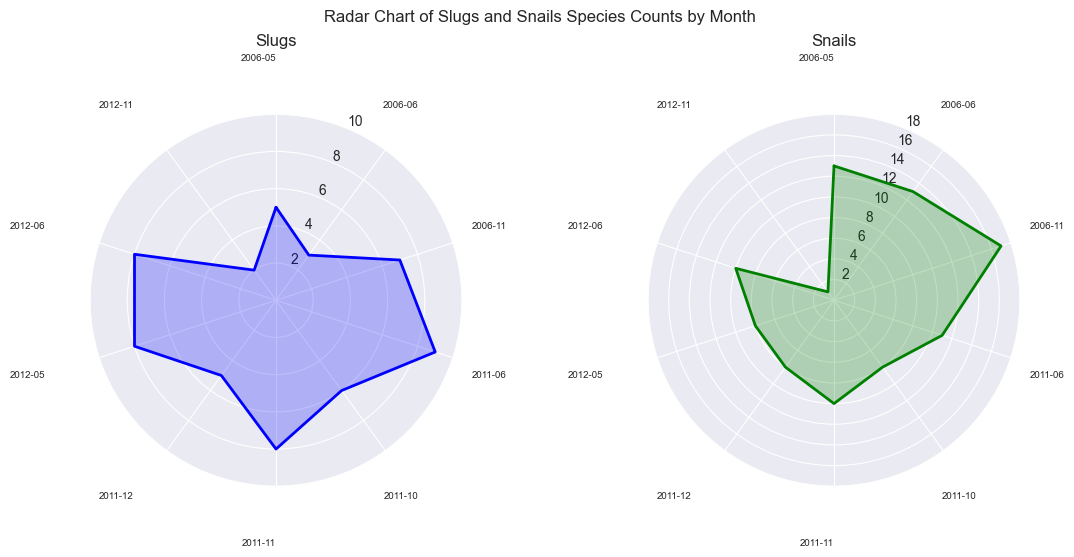

In [408]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data from CSV file
data = pd.read_csv("Slugs+and+Snails.csv")

# Convert 'Date' to datetime and extract Year-Month
data['Date'] = pd.to_datetime(data['Date'])
data['Year-Month'] = data['Date'].dt.to_period('M').astype(str)

# Aggregate counts by Year-Month and Type
grouped_counts = data.groupby(['Year-Month', 'Type'])['ScientificName'].nunique().unstack(fill_value=0)

# Prepare data for radar plot
categories = grouped_counts.index.tolist()  # Months
values_slug = grouped_counts['Slug'].values.flatten().tolist()
values_snail = grouped_counts['Snail'].values.flatten().tolist()

# Calculate maximum values for y-axis limits
maxslug = max(values_slug) + 1
maxsnail = max(values_snail) + 1
maxvalue = max(maxslug, maxsnail)

# Radar chart setup
N = len(categories)  # Total number of categories (months)

# Create a list of angles for each category
angles = [n / float(N) * 2 * np.pi for n in range(N)]

# Close the circle for radar chart
values_slug += values_slug[:1]
values_snail += values_snail[:1]
angles += angles[:1]

# Create the figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), subplot_kw={'projection': 'polar'})

# Plot slugs
ax1.set_title('Slugs')
ax1.set_theta_offset(np.pi / 2)  # Rotate the plot
ax1.set_theta_direction(-1)  # Reverse the direction
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(categories, fontsize=7)
for label in ax1.get_xticklabels():
    label.set_rotation(45)
    label.set_horizontalalignment('right')
ax1.tick_params(axis='x', pad=30)
ax1.set_ylim(0, maxslug)
ax1.xaxis.grid(True)
ax1.plot(angles, values_slug, color='blue', linewidth=2, linestyle='solid', label='Slugs')
ax1.fill(angles, values_slug, color='blue', alpha=0.25)

# Plot snails
ax2.set_title('Snails')
ax2.set_theta_offset(np.pi / 2)  # Rotate the plot
ax2.set_theta_direction(-1)  # Reverse the direction
ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(categories, fontsize=7)
for label in ax2.get_xticklabels():
    label.set_rotation(45)
    label.set_horizontalalignment('right')
ax2.tick_params(axis='x', pad=30)
ax2.set_ylim(0, maxsnail)
ax2.xaxis.grid(True)
ax2.plot(angles, values_snail, color='green', linewidth=2, linestyle='solid', label='Snails')
ax2.fill(angles, values_snail, color='green', alpha=0.25)

# Adjust spacing between subplots
plt.subplots_adjust(wspace=0.5)

# Add a title for the figure
fig.suptitle('Radar Chart of Slugs and Snails Species Counts by Month')

plt.show()
